# Livestock Feed Stockout-Risk Prediction — ML Prototype

Train, evaluate, and export a Random Forest classifier to estimate whether an ingredient could stock out within the next 7 days.

**Important limitation:** we currently have only a one-day mandi price snapshot and no real farm inventory/consumption/order history. This notebook therefore uses synthetic operational data to demonstrate the ML pipeline. Metrics are synthetic-only and must not be presented as real-world predictive performance.

## 1. Imports and setup

In [1]:
import os, json, joblib, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
OUT = Path("/kaggle/working/livestock_stockout_ml")
OUT.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUT)

Output directory: /kaggle/working/livestock_stockout_ml


## 2. Create a labelled synthetic dataset

In [2]:
N = 12000
names = np.array(["Green fodder", "Dry fodder", "Concentrate", "Maize", "Oil cake"])
ingredient = rng.choice(names, N, p=[.28, .20, .22, .18, .12])
daily_demand = np.clip(rng.lognormal(1.6, .55, N), .5, 30)
days_of_stock = rng.uniform(0, 18, N)
current_stock = daily_demand * days_of_stock
lead_time = rng.integers(1, 9, N)
open_orders = rng.uniform(0, 8, N) * daily_demand
reliability = rng.uniform(.65, 1.0, N)
price_change = rng.normal(.03, .15, N).clip(-.35, .65)
demand_change = rng.normal(.02, .18, N).clip(-.40, .70)
safety_days = rng.uniform(0, 7, N)
budget_pressure = rng.uniform(0, 1, N)
seasonal_index = rng.uniform(.75, 1.35, N)

effective_demand = daily_demand * (1 + demand_change).clip(.4, 1.8)
expected_available = current_stock + open_orders * reliability
expected_demand_7d = effective_demand * 7
risk = (
    1.25 * (expected_demand_7d - expected_available) / (daily_demand * 7 + 1e-6)
    + .12 * (lead_time / reliability - days_of_stock)
    - .18 * safety_days + .65 * demand_change
    + .45 * (1 - reliability) + .30 * budget_pressure
    + .18 * price_change + .20 * (seasonal_index - 1)
    + rng.normal(0, .45, N)
)
target = (risk > np.quantile(risk, .68)).astype(int)

data = pd.DataFrame({
    "ingredient": ingredient,
    "current_stock_kg": current_stock,
    "daily_demand_kg": daily_demand,
    "days_of_stock": days_of_stock,
    "lead_time_days": lead_time,
    "open_orders_qty_kg": open_orders,
    "supplier_reliability": reliability,
    "price_change_pct": price_change,
    "demand_change_pct": demand_change,
    "safety_stock_days": safety_days,
    "budget_pressure": budget_pressure,
    "seasonal_demand_index": seasonal_index,
    "stockout_within_7d": target
})
data.to_csv(OUT / "synthetic_stockout_training_data.csv", index=False)
print("Dataset:", data.shape)
print("Synthetic stockout label rate:", round(data.stockout_within_7d.mean(), 3))
display(data.head())

Dataset: (12000, 13)
Synthetic stockout label rate: 0.32


,ingredient,current_stock_kg,daily_demand_kg,days_of_stock,lead_time_days,open_orders_qty_kg,supplier_reliability,price_change_pct,demand_change_pct,safety_stock_days,budget_pressure,seasonal_demand_index,stockout_within_7d
0,Maize,31.855291,5.773370,5.517626,6,29.735225,0.706977,-0.070312,-0.013498,5.969593,0.836671,1.071848,1
1,Dry fodder,36.041644,2.543835,14.168231,6,8.043509,0.749817,0.143834,-0.159278,3.237681,0.943386,1.333460,0
2,Maize,13.308142,3.963983,3.357265,2,29.084707,0.803654,0.157723,0.032299,0.575671,0.684365,0.958183,1
3,Concentrate,12.314142,3.487022,3.531421,1,14.688719,0.728990,0.017719,0.145012,6.812894,0.726859,0.792611,1
4,Green fodder,21.342717,2.879775,7.411244,1,17.290587,0.768043,0.051788,0.076323,2.161184,0.932566,0.830800,0


## 3. Train/test split and train the model

In [3]:
FEATURES = [
    "ingredient", "current_stock_kg", "daily_demand_kg", "days_of_stock",
    "lead_time_days", "open_orders_qty_kg", "supplier_reliability",
    "price_change_pct", "demand_change_pct", "safety_stock_days",
    "budget_pressure", "seasonal_demand_index"
]
TARGET = "stockout_within_7d"
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=RANDOM_STATE, stratify=y
)

cat = ["ingredient"]
num = [c for c in FEATURES if c not in cat]
prep = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), num)
])
model = Pipeline([
    ("prep", prep),
    ("rf", RandomForestClassifier(
        n_estimators=250, max_depth=12, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ))
])
model.fit(X_train, y_train)
print("Training complete. Train rows:", len(X_train), "Test rows:", len(X_test))

Training complete. Train rows: 9600 Test rows: 2400


## 4. Evaluate on the held-out synthetic test set

,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.91125,0.820809,0.924479,0.869565,0.976105,0.952519


              precision    recall  f1-score   support

 No stockout       0.96      0.91      0.93      1632
    Stockout       0.82      0.92      0.87       768

    accuracy                           0.91      2400
   macro avg       0.89      0.91      0.90      2400
weighted avg       0.92      0.91      0.91      2400



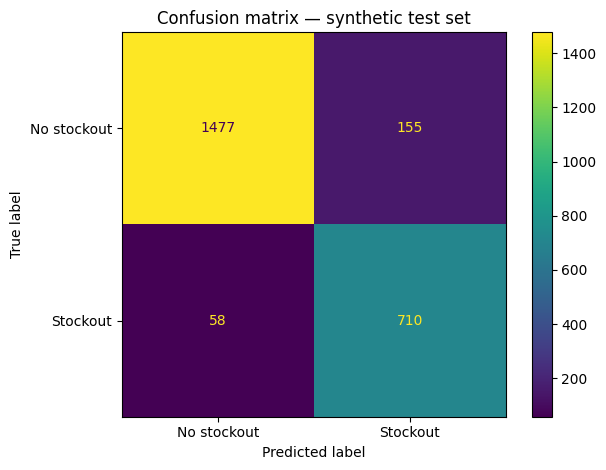

In [4]:
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred, zero_division=0),
    "f1": f1_score(y_test, pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, prob),
    "average_precision": average_precision_score(y_test, prob)
}])
display(metrics)
print(classification_report(y_test, pred, target_names=["No stockout", "Stockout"], zero_division=0))
metrics.to_csv(OUT / "synthetic_test_metrics.csv", index=False)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No stockout", "Stockout"])
plt.title("Confusion matrix — synthetic test set")
plt.tight_layout()
plt.show()

## 5. Feature importance

,feature,importance
7,num__days_of_stock,0.525672
5,num__current_stock_kg,0.229723
13,num__safety_stock_days,0.041874
6,num__daily_demand_kg,0.041571
12,num__demand_change_pct,0.039678
9,num__open_orders_qty_kg,0.028468
8,num__lead_time_days,0.028047
10,num__supplier_reliability,0.023499
14,num__budget_pressure,0.013531
11,num__price_change_pct,0.012118


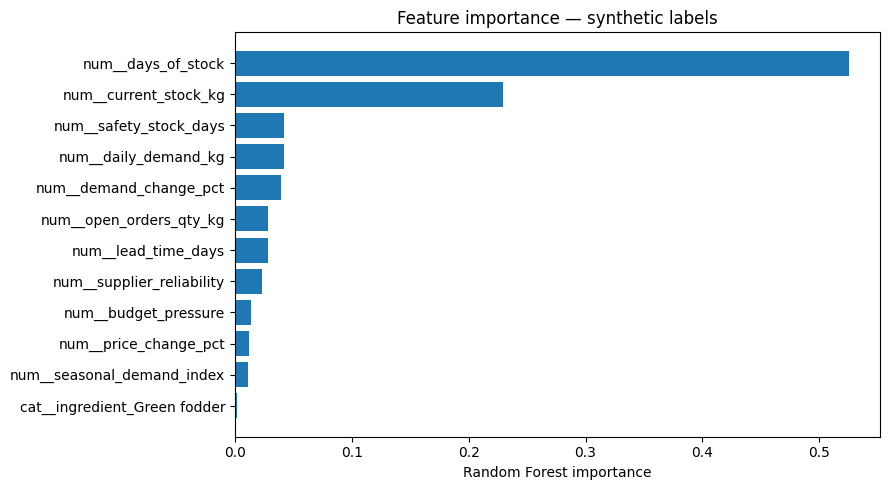

In [5]:
feature_names = model.named_steps["prep"].get_feature_names_out()
importances = model.named_steps["rf"].feature_importances_
importance = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
display(importance.head(15))
importance.to_csv(OUT / "synthetic_feature_importance.csv", index=False)
top = importance.head(12).sort_values("importance")
plt.figure(figsize=(9, 5))
plt.barh(top.feature, top.importance)
plt.title("Feature importance — synthetic labels")
plt.xlabel("Random Forest importance")
plt.tight_layout()
plt.show()

## 6. Score an illustrative observation

In [6]:
example = pd.DataFrame([{
    "ingredient": "Green fodder", "current_stock_kg": 22.0,
    "daily_demand_kg": 8.0, "days_of_stock": 2.75, "lead_time_days": 4,
    "open_orders_qty_kg": 5.0, "supplier_reliability": .80,
    "price_change_pct": .15, "demand_change_pct": .10,
    "safety_stock_days": 2.0, "budget_pressure": .60,
    "seasonal_demand_index": 1.10
}])
p = float(model.predict_proba(example[FEATURES])[0, 1])
label = int(model.predict(example[FEATURES])[0])
print("Illustrative synthetic-model risk score:", f"{p:.1%}")
print("Prediction:", "Stockout within 7 days" if label else "No stockout within 7 days")
print("Do not use this synthetic prototype as a real farm forecast.")

Illustrative synthetic-model risk score: 97.5%
Prediction: Stockout within 7 days
Do not use this synthetic prototype as a real farm forecast.


## 7. Save model and metadata

In [7]:
model_path = OUT / "stockout_risk_random_forest_synthetic.joblib"
joblib.dump(model, model_path)
metadata = {
    "model_type": "RandomForestClassifier pipeline",
    "target": "stockout_within_7d",
    "horizon_days": 7,
    "training_data": "synthetic, simulator-generated labels",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "warning": "Metrics and predictions are synthetic-data demonstrations, not validated real-world performance."
}
(OUT / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model:", model_path)

Saved model: /kaggle/working/livestock_stockout_ml/stockout_risk_random_forest_synthetic.joblib


## 8. Export all outputs to a ZIP

In [8]:
zip_base = "/kaggle/working/livestock_stockout_prediction_ml_results"
if os.path.exists(zip_base + ".zip"):
    os.remove(zip_base + ".zip")
shutil.make_archive(zip_base, "zip", root_dir=OUT)
print("Created:", zip_base + ".zip")
print("Contents:")
for f in sorted(OUT.iterdir()):
    print("-", f.name)

Created: /kaggle/working/livestock_stockout_prediction_ml_results.zip
Contents:
- model_metadata.json
- stockout_risk_random_forest_synthetic.joblib
- synthetic_feature_importance.csv
- synthetic_stockout_training_data.csv
- synthetic_test_metrics.csv


In [9]:
from IPython.display import FileLink, display
display(FileLink("/kaggle/working/livestock_stockout_prediction_ml_results.zip"))

/kaggle/working/livestock_stockout_prediction_ml_results.zip

## 9. How to make this a real predictive model

Replace the synthetic dataset with actual dated farm records, including opening stock, actual consumption, deliveries, order dates, supplier lead times, and whether stockout occurred within the following 7 days. For real records, use a chronological train/validation/test split and compare against a simple baseline. Do not report these synthetic metrics as real-world performance.